In [190]:
# import群
import os
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Hiragino Sans'  # macOS標準日本語フォント

# ランダムフォレスト
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import importlib
# utilsフォルダ内のモジュールをインポート
from utils import data_utils
from utils import preprocess
from utils import feature_extraction

# 修正を反映
importlib.reload(data_utils)
importlib.reload(preprocess)
importlib.reload(feature_extraction)

# 必要な関数やクラスを再度ノートブックに取り込む
from utils.data_utils import *
from utils.preprocess import *
from utils.feature_extraction import *

In [156]:
# 定数
LABEL_COUNT = 18 # ラベル数
SAMPLING_RATE = 80  # サンプリングレート

data_folder = "../data/20250809"

file_paths = [f for f in os.listdir(data_folder) if f.endswith('.txt')]

for i in range(len(file_paths)):
    print(f"{i:2}:{file_paths[i]}")

# row_data = []
# row_csi = []

# row_amp = []    # 振幅
# row_phase = []  # 位相

# # 前処理
# buttter_filtered__csi = []
# median_filtered_csi = []

# # 分割
# split_data = []
# split_csi = []
# merged_split_data = []  # [ラベル][分割後データ数][データ]
# merged_split_csi = []   # [ラベル][分割後データ数][CSI]

# # クラス数を削減
# restored_split_csi = []

 0:20250809_161644_data.txt
 1:20250809_161047_data.txt
 2:20250809_162821_data.txt
 3:20250809_162443_data.txt
 4:20250809_160455_data.txt
 5:20250809_160802_data.txt
 6:20250809_162150_data.txt
 7:20250809_161336_data.txt
 8:20250809_161904_data.txt
 9:20250809_160221_data.txt


In [89]:
# file_paths を最初の 8 個と後ろの 2 個に分ける
test_file_paths = file_paths[-2:]  # 後ろの 2 個
file_paths = file_paths[:8]  # 最初の 8 個

for i in range(len(file_paths)):
    print(f"{i:2}:{file_paths[i]}")

for i in range(len(test_file_paths)):
    print(f"{i:2}:{test_file_paths[i]}")

 0:20251007_084040_data.txt
 1:20251007_083701_data.txt
 2:20251007_085055_data.txt
 3:20251007_084434_data.txt
 4:20251007_085535_data.txt
 5:20251007_091117_data.txt
 6:20251007_090435_data.txt
 7:20251007_092053_data.txt
 0:20251007_093215_data.txt
 1:20251007_092725_data.txt


In [191]:
# row_data/row_csiにデータを格納する
row_data, row_csi = load_csi_data(LABEL_COUNT, data_folder, file_paths)

# 振幅と位相を分割
row_amp, row_phase = split_amp_phase(row_csi)

# 振幅・位相を計算
amplitude, phase = calculate_amplitude_and_phase(row_amp, row_phase)


In [172]:
def calculate_amplitude(row_csi):
    """
    row_csi の各サブキャリア値を振幅に変換する。

    Args:
        row_csi: [ラベル][ファイル][行][サブキャリア値1(実部), サブキャリア値2(虚部), ...]

    Returns:
        amplitude_row_amp: [ラベル][ファイル][行][サブキャリア値1(振幅), サブキャリア値2(振幅), ...]
    """
    amplitude_row_amp = []
    for label in row_amp:
        label_amplitude = []
        for file in label:
            file_amplitude = []
            for row in file:
                # 実部と虚部をペアにして振幅を計算
                amplitude = [np.sqrt(row[i]**2 + row[i+1]**2) for i in range(0, len(row), 2)]
                file_amplitude.append(amplitude)
            label_amplitude.append(file_amplitude)
        amplitude_row_amp.append(label_amplitude)
    return amplitude_row_amp

row_amp = calculate_amplitude(row_csi)

# 結果の確認
# print("元のデータ:", row_amp)
# print("振幅データ:", amplitude_row_amp)

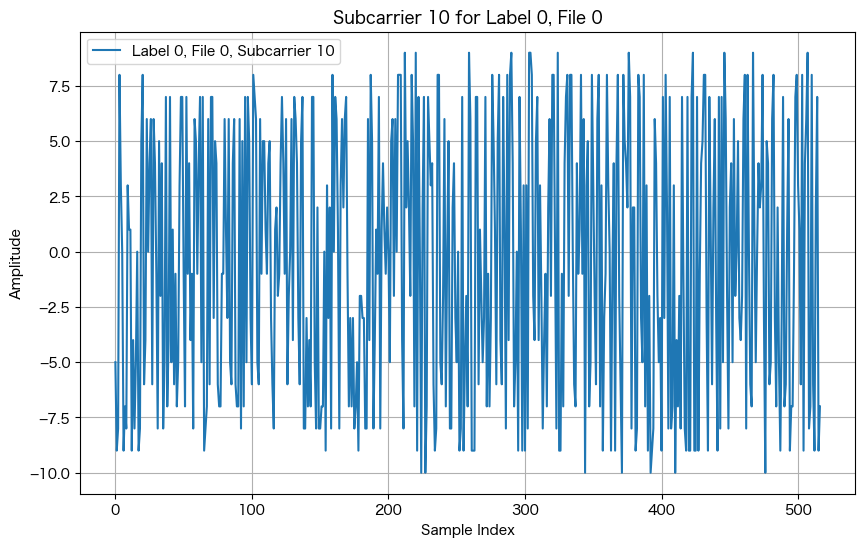

In [173]:
def plot_specific_subcarrier(row_amp, label_idx, file_idx, subcarrier_idx):
    """
    特定のサブキャリアをプロットする。

    Args:
        row_amp: [ラベル][ファイル][行][サブキャリア値]
        label_idx: プロットするラベルのインデックス
        file_idx: プロットするファイルのインデックス
        subcarrier_idx: プロットするサブキャリアのインデックス
    """
    # 指定したラベルとファイルのデータを取得
    data = row_amp[label_idx][file_idx]
    
    # 指定したサブキャリアの値を抽出
    subcarrier_values = [row[subcarrier_idx] for row in data]
    
    # プロット
    plt.figure(figsize=(10, 6))
    plt.plot(subcarrier_values, label=f"Label {label_idx}, File {file_idx}, Subcarrier {subcarrier_idx}")
    plt.title(f"Subcarrier {subcarrier_idx} for Label {label_idx}, File {file_idx}")
    plt.xlabel("Sample Index")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.grid()
    plt.show()

# 使用例
# ラベル0、ファイル0、サブキャリア10をプロット
plot_specific_subcarrier(row_phase, label_idx=0, file_idx=0, subcarrier_idx=10)

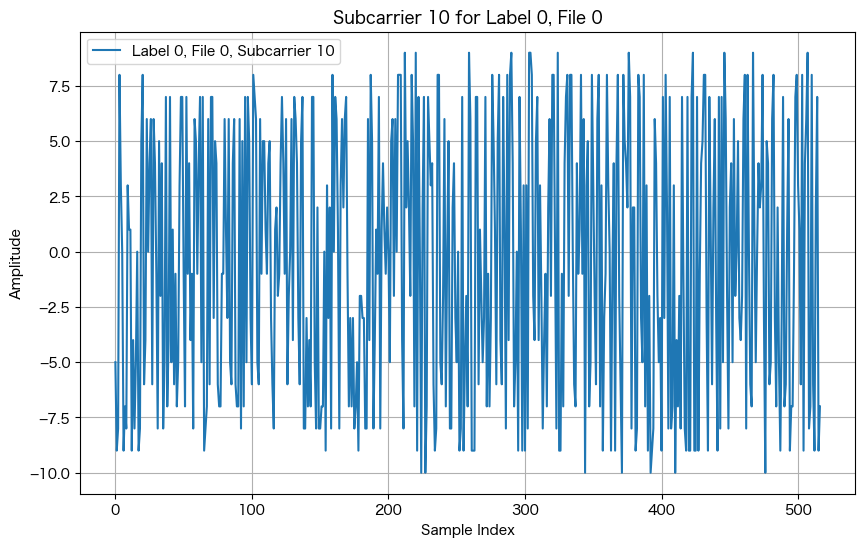

In [174]:
plot_specific_subcarrier(row_phase, label_idx=0, file_idx=0, subcarrier_idx=10)

In [ ]:
# (test)test_row_data/test_row_csiにデータを格納する
test_row_data, test_row_csi = load_csi_data(LABEL_COUNT, data_folder, test_file_paths)

# 振幅と位相を分割
test_row_amp, test_row_phase = split_amp_phase(test_row_csi)

In [236]:
row_amp = amplitude
row_phase = phase

In [199]:
row_amp = row_phase

In [ ]:
row_amp = row_csi

In [ ]:
# (test)
test_row_amp = test_row_phase

In [237]:
# row_ampとrow_phaseを結合
def combine_amp_and_phase(row_amp, row_phase):
    """
    row_amp（振幅）とrow_phase（位相）を一つのリスト配列にまとめる。

    Args:
        row_amp: [ラベル][ファイル][行][サブキャリア値(振幅)]
        row_phase: [ラベル][ファイル][行][サブキャリア値(位相)]

    Returns:
        combined: [ラベル][ファイル][行][サブキャリア値(振幅, 位相)]
    """
    combined = []
    for label_amp, label_phase in zip(row_amp, row_phase):
        combined_label = []
        for file_amp, file_phase in zip(label_amp, label_phase):
            combined_file = []
            for amp_row, phase_row in zip(file_amp, file_phase):
                # 振幅と位相を交互に並べる
                combined_row = [val for pair in zip(amp_row, phase_row) for val in pair]
                combined_file.append(combined_row)
            combined_label.append(combined_file)
        combined.append(combined_label)
    return combined

# 先に位相回転の補正
row_phase = correct_phase_rotation(phase)

# 使用例
row_amp = combine_amp_and_phase(row_amp, row_phase)

In [ ]:
print(row_amp[0][0][10])
print(row_phase[0][0][10])

[np.float64(0.0), np.float64(3.5236644996518316), np.float64(0.0), np.float64(3.5104847370839702), np.float64(0.0), np.float64(3.497304974516109), np.float64(0.0), np.float64(3.484125211948247), np.float64(0.0), np.float64(3.4709454493803857), np.float64(0.0), np.float64(3.4577656868125244), np.float64(10.04987562112089), np.float64(0.4026619231460318), np.float64(9.0), np.float64(0.289813508087009), np.float64(9.055385138137417), np.float64(0.16597652434525223), np.float64(9.0), np.float64(0.2634539829512863), np.float64(9.055385138137417), np.float64(0.13961699920952952), np.float64(8.06225774829855), np.float64(0.11273946326880235), np.float64(8.06225774829855), np.float64(0.09955970070094056), np.float64(8.246211251235321), np.float64(-0.03424373044702378), np.float64(8.06225774829855), np.float64(0.07320017556521785), np.float64(8.54400374531753), np.float64(-0.17439526272645445), np.float64(8.54400374531753), np.float64(-0.1875750252943158), np.float64(8.54400374531753), np.float

In [ ]:
# row_ampのサブキャリアを制限
row_amp = row_phase

# HT-LTFのサブキャリアを抽出（66~93, 95~123）
row_amp = [
    [
        [ [v for i, v in enumerate(row[66:], start=66) if i != 94] 
          for row in file ]
        for file in label
    ]
    for label in row_amp
]

In [ ]:
# row_ampのサブキャリアを制限
row_amp = row_phase

# HT-LTFのサブキャリアを抽出（66~93, 95~123）
row_amp = [
    [
        [ [v for i, v in enumerate(row[66:123], start=66) if i != 94] 
          for row in file ]
        for file in label
    ]
    for label in row_amp
]

In [ ]:
# row_ampのサブキャリアを制限
row_amp = row_phase

# HT-LTFのサブキャリアを抽出（~66, 123~）
row_amp = [
    [
        [[v for i, v in enumerate(row) if not (66 <= i <= 123)] 
         for row in file]
        for file in label
    ]
    for label in row_amp
]

In [ ]:
print("ラベル数:      "+str(len(row_amp)))
print("ファイル数:    "+str(len(row_amp[0])))
print("レコード数:    "+str(len(row_amp[0][0])))
print("サブキャリア数: "+str(len(row_amp[0][0][0])))

print(row_amp[0][0][63])

ラベル数:      18
ファイル数:    10
レコード数:    517
サブキャリア数: 384
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -7, -7, -7, -5, -8, -5, -7, -5, -7, -5, -6, -4, -7, -4, -7, -3, -7, -3, -7, -3, -7, -3, -7, -3, -7, -2, -7, -2, -7, -2, -9, -1, -7, -1, -8, -1, -8, 0, -8, 0, -8, 0, -9, 0, -9, -1, -9, 0, -10, -1, -10, 0, 0, 0, -10, 0, -11, -1, -9, -1, -11, -1, -9, -1, -10, -1, -10, -1, -9, -1, -9, -1, -10, -1, -9, -2, -9, -2, -9, -2, -8, -1, -9, -2, -8, -2, -9, -2, -7, -2, -8, -2, -8, -2, -8, -2, -8, -2, -8, -3, -7, -3, -7, -4, -6, -4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -47, -27, -50, -23, -51, -17, -47, -14, -50, -19, -41, -17, -46, -13, -39, -12, -44, -14, -34, -9, -37, -8, -36, -8, -40, -4, -44, -5, -35, -4, -42, 4, -39, 2, -40, 8, -36, 5, -40, 14, -43, 19, -41, 8, -40, 12, -40, 15, -45, 15, -45, 20, -50, 17, -49, 16, -54, 15, -51, 19, -49, 14, -54, 14, -55, 16, -50, 17, -50, 15, -47, 7, -52, 15, -47, 14, -51, 11, -51, 14, -50, 15, -49, 8, -47, 9, -50, 11, -47, 8, -53, 12, -45, 7, -52, 5, -38, 5, -43, 8

In [ ]:
# (test)
print("ラベル数:      "+str(len(test_row_amp)))
print("ファイル数:    "+str(len(test_row_amp[0])))
print("レコード数:    "+str(len(test_row_amp[0][0])))
print("サブキャリア数: "+str(len(test_row_amp[0][0][0])))

print(test_row_amp[0][0][63])

ラベル数:      18
ファイル数:    2
レコード数:    1344
サブキャリア数: 192
[0, 0, 0, 0, 0, 0, -6, -5, -5, -5, -5, -5, -5, -5, -4, -5, -4, -4, -4, -3, -3, -3, -3, -2, -2, -2, -2, -2, -2, -1, -1, -1, 0, -1, -1, -1, -2, -2, -2, -2, -2, -2, -3, -3, -3, -3, -3, -3, -3, -3, -3, -4, -4, -4, -4, -4, -4, -4, -5, 0, 0, 0, 0, 0, 0, 0, 29, 30, 28, 16, 25, 21, 22, 15, 23, 17, 19, 17, 21, 17, 12, 14, 15, 18, 8, 6, 8, 9, 3, 2, 0, 3, 6, 2, 2, 2, 2, 1, -2, -2, 4, -1, -2, 1, -1, 6, 6, 9, 5, 9, 7, 9, 11, 8, 5, 11, 1, 11, 13, 15, 21, 15, 16, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 36, 36, 39, 34, 40, 42, 40, 48, 46, 50, 46, 52, 48, 54, 53, 59, 49, 59, 56, 58, 58, 51, 50, 51, 53, 52, 56, 49, 47, 48, 48, 44, 52, 54, 52, 53, 46, 49, 53, 50, 50, 51, 48, 56, 55, 46, 51, 58, 57, 62, 60, 66, 61, 60, 57, 61, 70, 0]


In [ ]:
# row_dataから常に0のサブキャリアを削除する
row_amp, orig_subcarriers_num, new_subcarriers_num= remove_zero_subcarriers(row_amp)

print(f"元のサブキャリア数: {orig_subcarriers_num}")
print(f"削除後のサブキャリア数: {new_subcarriers_num}")

元のサブキャリア数: 60
削除後のサブキャリア数: 57


In [ ]:
# 前処理：バターワースフィルタ
row_amp, plt_obj = butter_lowpass_filter_csi(row_amp, SAMPLING_RATE)
# plt_obj.show()

# 前処理：メディアンフィルタ
row_amp, plt_obj = median_filter_csi(row_amp)
# plt_obj.show()

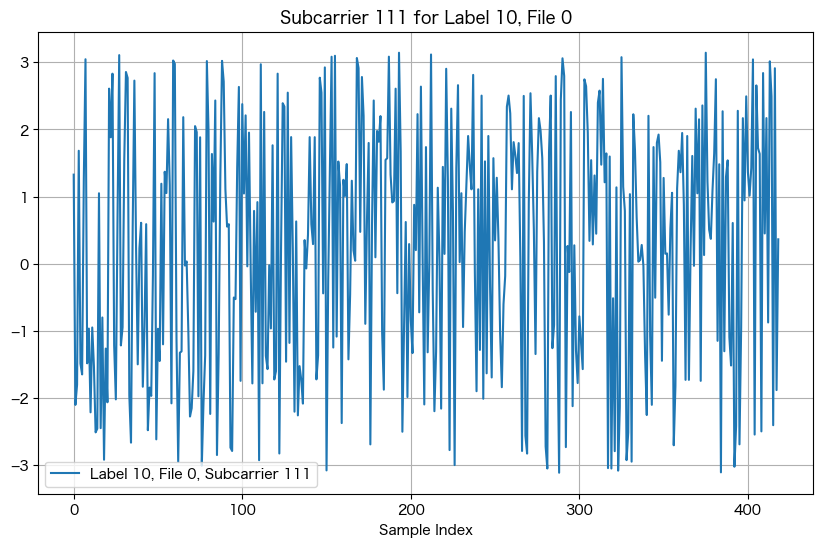

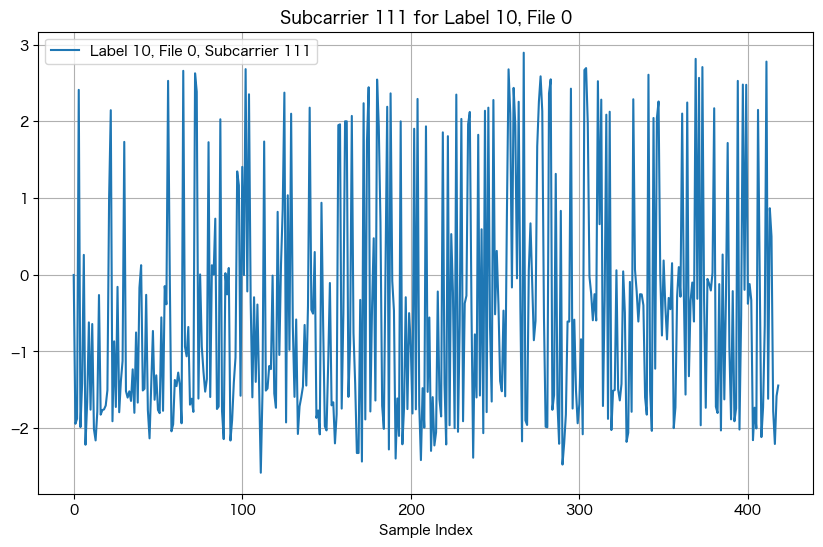

In [200]:
# 位相のアンラップと位相キャリブレーション
plot_row_amp(row_amp, label_idx=10, file_idx=0, subcarrier_idx=111)
row_amp = correct_phase_rotation(phase)
plot_row_amp(row_amp, label_idx=10, file_idx=0, subcarrier_idx=111)

In [247]:
# 500msごとに分割（各ファイルの先頭msを基準に相対時間で分割）
split_data, split_csi = split_by_interval(row_data, row_amp, interval_ms=500)

# 各ラベルごとに全ファイルの分割データを連結する
merged_split_data, merged_split_csi = merge_split_data(split_data, split_csi)

In [ ]:
# 500msごとに分割（各ファイルの先頭msを基準に相対時間で分割）
split_data, split_csi = split_by_sliding_window(row_data, row_amp, window_ms=500, step_ms=100)

# 各ラベルごとに全ファイルの分割データを連結する
merged_split_data, merged_split_csi = merge_split_data(split_data, split_csi)

In [ ]:
# (test)500msごとに分割（各ファイルの先頭msを基準に相対時間で分割）
test_split_data, test_split_csi = split_by_sliding_window(test_row_data, test_row_amp, window_ms=500, step_ms=100)

# 各ラベルごとに全ファイルの分割データを連結する
test_merged_split_data, test_merged_split_csi = merge_split_data(test_split_data, test_split_csi)

In [248]:
# クラスの削減

# 使いたいラベルのインデックス
target_labels = [[0, 1], [3], [5, 6],
                 [21, 22], [24], [26, 27]]

target_labels = [[0, 1, 7, 8, 14, 15, 21, 22, 28, 29, 35, 36], 
                 [2, 3, 4, 9, 10, 11, 16, 17, 18, 23, 24, 25, 30, 31, 32, 37, 38, 39],
                 [5, 6, 12, 13, 19, 20, 26, 27, 33, 34, 40, 41]]

target_labels = [[0, 1], [3], [5, 6],
                 [21, 22], [24], [26, 27]]

target_labels = [[0], [1], [2], [9], [10], [11]]
# target_labels = [[0,3,6], [1,4,7], [2,5,8], [9,12,15], [10,13,16], [11,14,17]]
# target_labels = [[0,3,6,9,12,15], [1,4,7,10,13,16], [2,5,8,11,14,17]]


# クラス削減（ラベルグループ化）を関数で実行
restored_split_csi = group_labels_by_indices(merged_split_csi, target_labels)

print(len(restored_split_csi[0]))
print(len(merged_split_csi[0]))

135
135


In [249]:
print(restored_split_csi[0][0][0])
print(len(restored_split_csi[0][0][0]))

[np.float64(0.0), np.float64(1.8383373242580663), np.float64(0.0), np.float64(1.8730744113783153), np.float64(0.0), np.float64(1.9078114984985641), np.float64(0.0), np.float64(1.9425485856188132), np.float64(0.0), np.float64(1.977285672739062), np.float64(0.0), np.float64(2.012022759859311), np.float64(10.816653826391969), np.float64(-0.5068302030626657), np.float64(9.433981132056603), np.float64(-0.5014964041464216), np.float64(11.180339887498949), np.float64(-0.5617110233689293), np.float64(9.848857801796104), np.float64(-0.5723972156702573), np.float64(11.180339887498949), np.float64(-0.49223684912843124), np.float64(7.615773105863909), np.float64(-0.516255584723905), np.float64(8.54400374531753), np.float64(-0.5276396136181676), np.float64(8.54400374531753), np.float64(-0.49290252649791855), np.float64(8.06225774829855), np.float64(-0.6925811151014805), np.float64(9.055385138137417), np.float64(-0.6715418013540972), np.float64(9.055385138137417), np.float64(-0.6368047142338482), np

In [ ]:
# (test)クラスの削減
test_restored_split_csi = group_labels_by_indices(test_merged_split_csi, target_labels)

print(len(test_restored_split_csi[0]))
print(len(test_merged_split_csi[0]))

237
237


In [ ]:
# 2つ目のデータセット
data_folder2 = "../data/20250630"
data_folder2 = "../data/20250809"
file_paths2 = [f for f in os.listdir(data_folder2) if f.endswith('.txt')]
# row_data2, row_csi2 = load_csi_data(42, data_folder2, file_paths2)
row_data2, row_csi2 = load_csi_data(18, data_folder2, file_paths2)
row_amp2, row_phase2 = split_amp_phase(row_csi2)

# HT-LTFのサブキャリアを抽出（66~93, 95~123）
# row_amp2 = row_phase2
# row_amp2 = [
#     [
#         [ [v for i, v in enumerate(row[66:123], start=66) if i != 94] 
#           for row in file ]
#         for file in label
#     ]
#     for label in row_amp2
# ]

# ゼロサブキャリアの除去
# row_amp2, orig_subcarriers_num2, new_subcarriers_num2 = remove_zero_subcarriers(row_amp2)
# print(f"元のサブキャリア数: {orig_subcarriers_num2}")
# print(f"削除後のサブキャリア数: {new_subcarriers_num2}")

# 前処理（必要に応じて変更）
# buttter_filtered__csi2, _ = butter_lowpass_filter_csi(row_amp2, SAMPLING_RATE)
# median_filtered_csi2, _ = median_filter_csi(row_amp2)

# 分割・連結
# split_data2, split_csi2 = split_by_interval(row_data2, row_amp2, interval_ms=500)
split_data2, split_csi2 = split_by_sliding_window(row_data2, row_amp2, window_ms=500, step_ms=100)
merged_split_data2, merged_split_csi2 = merge_split_data(split_data2, split_csi2)

# クラス削減（ラベルグループ化）
target_labels2 = [[0,1], [3], [5,6], [21,22], [24], [26,27]]
target_labels2 = [[0], [1], [2], [9], [10], [11]]
# target_labels2 = [[0,1,21,22], [3,24], [5,6,26,27]]
restored_split_csi2 = group_labels_by_indices(merged_split_csi2, target_labels2)

# データマージ
merged_restored_split_csi = []
for csi1, csi2 in zip(restored_split_csi, restored_split_csi2):
    merged_restored_split_csi.append(csi1 + csi2)

restored_split_csi = merged_restored_split_csi

In [250]:
# 特徴量抽出と特徴量名リスト作成（13種類＋追加特徴量）
X_train, y_train, feature_names = create_feature_matrix(restored_split_csi, SAMPLING_RATE, 
                                            use_additional=False)
                                            # feature_list=["二乗平均平方根", "標準偏差", "最大値", "最小値"])

print(f"抽出された特徴量数: {len(feature_names)}")
print("特徴量名リスト例:", feature_names)
# 統計特徴量
stat_features = extract_features_per_subcarrier(restored_split_csi[0][0])[10]
print("統計特徴量:", stat_features)

# 追加特徴量
# if(additional_features):
#     add_features = extract_additional_features_per_subcarrier(restored_split_csi[0][0], SAMPLING_RATE)[0]
#     print("追加特徴量:", add_features)

/Users/tanakakeiji/研究コード/reserch-analysis/venv/lib/python3.9/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


抽出された特徴量数: 4992
特徴量名リスト例: ['subc0_平均', 'subc0_中央値', 'subc0_標準偏差', 'subc0_最大値', 'subc0_最小値', 'subc0_上四分位値', 'subc0_下四分位値', 'subc0_四分位範囲', 'subc0_平均絶対偏差', 'subc0_尖度', 'subc0_歪度', 'subc0_自己相関', 'subc0_二乗平均平方根', 'subc1_平均', 'subc1_中央値', 'subc1_標準偏差', 'subc1_最大値', 'subc1_最小値', 'subc1_上四分位値', 'subc1_下四分位値', 'subc1_四分位範囲', 'subc1_平均絶対偏差', 'subc1_尖度', 'subc1_歪度', 'subc1_自己相関', 'subc1_二乗平均平方根', 'subc2_平均', 'subc2_中央値', 'subc2_標準偏差', 'subc2_最大値', 'subc2_最小値', 'subc2_上四分位値', 'subc2_下四分位値', 'subc2_四分位範囲', 'subc2_平均絶対偏差', 'subc2_尖度', 'subc2_歪度', 'subc2_自己相関', 'subc2_二乗平均平方根', 'subc3_平均', 'subc3_中央値', 'subc3_標準偏差', 'subc3_最大値', 'subc3_最小値', 'subc3_上四分位値', 'subc3_下四分位値', 'subc3_四分位範囲', 'subc3_平均絶対偏差', 'subc3_尖度', 'subc3_歪度', 'subc3_自己相関', 'subc3_二乗平均平方根', 'subc4_平均', 'subc4_中央値', 'subc4_標準偏差', 'subc4_最大値', 'subc4_最小値', 'subc4_上四分位値', 'subc4_下四分位値', 'subc4_四分位範囲', 'subc4_平均絶対偏差', 'subc4_尖度', 'subc4_歪度', 'subc4_自己相関', 'subc4_二乗平均平方根', 'subc5_平均', 'subc5_中央値', 'subc5_標準偏差', 'subc5_最大値', 'subc5_最小値', 'su

In [ ]:
# (test)特徴量抽出と特徴量名リスト作成（13種類＋追加特徴量）
X_test, y_test, test_feature_names = create_feature_matrix(test_restored_split_csi, SAMPLING_RATE, 
                                            use_additional=False)

print(f"抽出された特徴量数: {len(test_feature_names)}")

抽出された特徴量数: 2496


In [ ]:
# 特徴量をプロット

import pandas as pd
import numpy as np

# DataFrame化
df = pd.DataFrame(X, columns=feature_names)
df['label'] = y

# ラベルごとに特徴量の平均・標準偏差を集計
summary = df.groupby('label').agg(['mean', 'std'])

# 平均値だけ抽出してヒートマップ表示
mean_df = summary.xs('mean', axis=1, level=1)
print(mean_df)

import seaborn as sns
plt.figure(figsize=(12,6))
sns.heatmap(mean_df, annot=True, fmt=".2f", cmap="viridis")
plt.title("ラベルごとの特徴量平均")
plt.show()

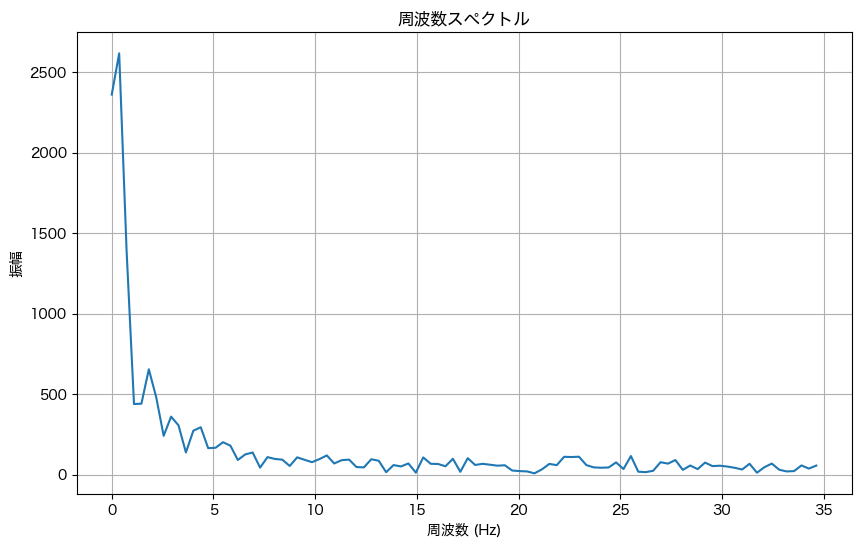

In [ ]:
# フーリエ変換を適用する関数

def analyze_fft(row_amp, sampling_rate):
    """
    row_ampにフーリエ変換を適用し、周波数スペクトルをプロットする

    Args:
        row_amp: [ラベル][ファイル][行][サブキャリア値]
        sampling_rate: サンプリングレート（Hz）
    """
    label_idx = 0  # 任意のラベルを選択
    file_idx = 0   # 任意のファイルを選択
    row_idx = 0    # 任意の行を選択

    # サンプルデータを取得
    sample_data = row_amp[label_idx][file_idx][row_idx]

    # フーリエ変換
    fft_result = np.fft.fft(sample_data)
    freqs = np.fft.fftfreq(len(sample_data), d=1/sampling_rate)

    # 振幅スペクトルを計算
    amplitude = np.abs(fft_result)

    # プロット
    plt.figure(figsize=(10, 6))
    plt.plot(freqs[:len(freqs)//2], amplitude[:len(amplitude)//2])  # 正の周波数のみプロット
    plt.title("周波数スペクトル")
    plt.xlabel("周波数 (Hz)")
    plt.ylabel("振幅")
    plt.grid()
    plt.show()

# フーリエ変換の解析を実行
analyze_fft(row_amp, SAMPLING_RATE)

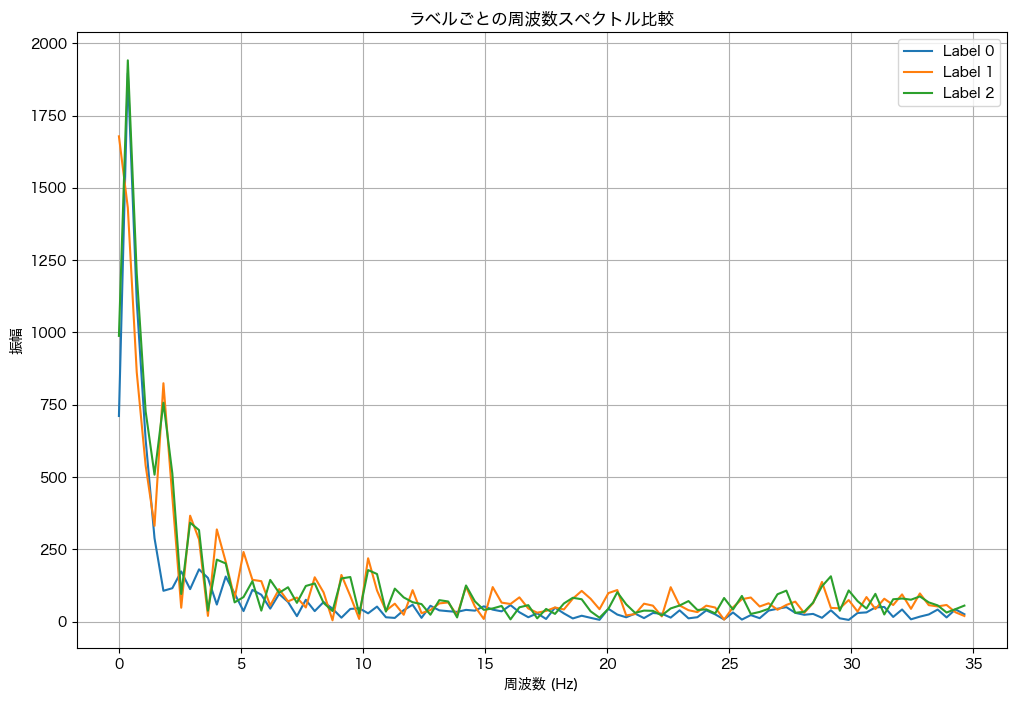

In [ ]:
# ラベルごとにフーリエ変換を描画・比較する関数
import numpy as np
import matplotlib.pyplot as plt

def compare_fft_by_labels(row_amp, sampling_rate, label_indices):
    """
    複数のラベルに対してフーリエ変換を適用し、周波数スペクトルを比較する

    Args:
        row_amp: [ラベル][ファイル][行][サブキャリア値]
        sampling_rate: サンプリングレート（Hz）
        label_indices: 比較するラベルのインデックスリスト
    """
    plt.figure(figsize=(12, 8))

    for label_idx in label_indices:
        # 任意のファイルと行を選択
        file_idx = 0
        row_idx = 0

        # サンプルデータを取得
        sample_data = row_amp[label_idx][file_idx][row_idx]

        # フーリエ変換
        fft_result = np.fft.fft(sample_data)
        freqs = np.fft.fftfreq(len(sample_data), d=1/sampling_rate)
        amplitude = np.abs(fft_result)

        # プロット
        plt.plot(freqs[:len(freqs)//2], amplitude[:len(amplitude)//2], label=f"Label {label_idx}")

    plt.title("ラベルごとの周波数スペクトル比較")
    plt.xlabel("周波数 (Hz)")
    plt.ylabel("振幅")
    plt.legend()
    plt.grid()
    plt.show()

# 使用例: ラベル0, 1, 2を比較
compare_fft_by_labels(row_amp, SAMPLING_RATE, label_indices=[0, 1, 2])

In [ ]:
# フーリエ変換による解析
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

def extract_fft_features(row_amp, sampling_rate):
    """
    row_ampにフーリエ変換を適用し、振幅スペクトルを特徴量として抽出

    Args:
        row_amp: [ラベル][ファイル][行][サブキャリア値]
        sampling_rate: サンプリングレート（Hz）

    Returns:
        X_fft: 特徴量行列 (サンプル数 x 特徴量数)
        y: ラベルリスト
    """
    X_fft = []
    y = []

    for label_idx, label in enumerate(reduced_row_amp):
        for file in label:
            for row in file:
                # フーリエ変換
                fft_result = np.fft.fft(row)
                amplitude = np.abs(fft_result[:len(fft_result)//2])  # 正の周波数のみ
                X_fft.append(amplitude)
                y.append(label_idx)  # ラベルを追加

    return np.array(X_fft), np.array(y)

# フーリエ変換で特徴量を抽出
X_fft, y = extract_fft_features(reduced_row_amp, SAMPLING_RATE)

# データ分割
X_train, X_test, y_train, y_test = train_test_split(X_fft, y, test_size=0.2, random_state=42, stratify=y)

# ランダムフォレストで学習・予測
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# 結果表示
print(classification_report(y_test, y_pred, digits=3))

In [251]:
# ランダムフォレスト

# データ分割
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_test, y_train, y_test = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

# ランダムフォレストで学習・予測
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# 結果表示
print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           0      0.625     0.556     0.588        27
           1      0.475     0.731     0.576        26
           2      0.750     0.480     0.585        25
           3      0.571     0.690     0.625        29
           4      0.652     0.556     0.600        27
           5      0.591     0.500     0.542        26

    accuracy                          0.588       160
   macro avg      0.611     0.585     0.586       160
weighted avg      0.609     0.588     0.587       160



In [ ]:
# 交差検証
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

clf = RandomForestClassifier(n_estimators=100, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)  # 5分割交差検証

scores = cross_val_score(clf, X_train, y_train, cv=cv, scoring='accuracy')
print(f"各foldの精度: {scores}")
print(f"平均精度: {scores.mean():.3f}")

各foldの精度: [0.421875   0.44094488 0.37007874 0.39370079 0.40944882]
平均精度: 0.407


In [252]:
# 特徴量重要度の取得
importances = clf.feature_importances_
indices = np.argsort(importances)[::-1]

# 上位特徴量を表示
if False:
    top_n = 20
    plt.figure(figsize=(10,6))

    plt.title("Feature Importances (Top {})".format(top_n))
    plt.bar(range(top_n), importances[indices][:top_n], align='center')
    plt.xticks(range(top_n), [feature_names[i] for i in indices[:top_n]], rotation=90)
    plt.tight_layout()
    plt.show()

In [253]:
# 上位特徴量のみで再学習・評価
res = 0
max_acc = 0
report_str = ""

res_min = 0
min_acc = 1
report_min = ""

for i in range(len(feature_names)):
    top_n = i + 1
    selected_indices = indices[:top_n]
    X_selected = [[x[i] for i in selected_indices] for x in X_train]

    # データ分割
    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_selected, y_train, test_size=0.2, random_state=42, stratify=y_train)

    clf_s = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    clf_s.fit(X_train_s, y_train_s)
    y_pred_s = clf_s.predict(X_test_s)

    report = classification_report(y_test_s, y_pred_s, digits=3, output_dict=True)
    if report['accuracy'] > max_acc:
        max_acc = report['accuracy']
        res = i
        report_str = classification_report(y_test_s, y_pred_s, digits=3)

    if report['accuracy'] < min_acc:
        min_acc = report['accuracy']
        res_min = i
        report_min = classification_report(y_test_s, y_pred_s, digits=3)

print(f"--- 上位{res+1}特徴量のみ ---")
print(report_str)

print(f"--- 上位{res_min+1}特徴量のみ ---")
print(report_min)

--- 上位393特徴量のみ ---
              precision    recall  f1-score   support

           0      0.850     0.773     0.810        22
           1      0.812     0.619     0.703        21
           2      0.789     0.750     0.769        20
           3      0.690     0.870     0.769        23
           4      0.652     0.714     0.682        21
           5      0.810     0.810     0.810        21

    accuracy                          0.758       128
   macro avg      0.767     0.756     0.757       128
weighted avg      0.766     0.758     0.758       128

--- 上位1特徴量のみ ---
              precision    recall  f1-score   support

           0      0.240     0.273     0.255        22
           1      0.214     0.143     0.171        21
           2      0.200     0.200     0.200        20
           3      0.148     0.174     0.160        23
           4      0.158     0.143     0.150        21
           5      0.174     0.190     0.182        21

    accuracy                          0.1

              precision    recall  f1-score   support

           0      0.850     0.773     0.810        22
           1      0.812     0.619     0.703        21
           2      0.789     0.750     0.769        20
           3      0.690     0.870     0.769        23
           4      0.652     0.714     0.682        21
           5      0.810     0.810     0.810        21

    accuracy                          0.758       128
   macro avg      0.767     0.756     0.757       128
weighted avg      0.766     0.758     0.758       128



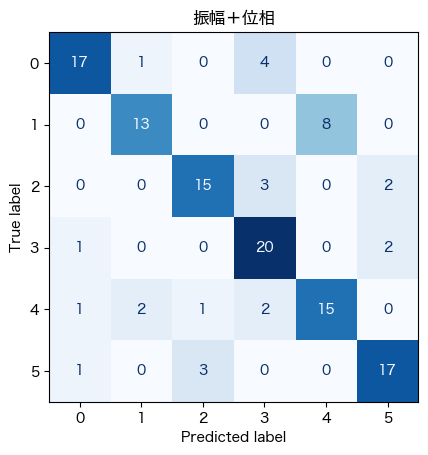

In [254]:
# 指定した特徴量数で再学習・評価
selected_indices = indices[:393]
X_selected = [[x[i] for i in selected_indices] for x in X_train]

# データ分割
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_selected, y_train, test_size=0.2, random_state=42, stratify=y_train)

clf_s = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
clf_s.fit(X_train_s, y_train_s)
y_pred_s = clf_s.predict(X_test_s)


# 結果表示
print(classification_report(y_test_s, y_pred_s, digits=3))

# 混同行列の表示
cm = confusion_matrix(y_test_s, y_pred_s)

# 混同行列の描画
ConfusionMatrixDisplay.from_predictions(
    y_test_s, 
    y_pred_s, 
    cmap="Blues",
    colorbar=False
)
plt.title("振幅＋位相")
plt.show()

In [ ]:
# 交差検証
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)  # 10分割交差検証

# 特徴量選択
selected_indices = indices[:156]
X_selected = [[x[i] for i in selected_indices] for x in X_train]

# ランダムフォレストモデル
clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

# 交差検証のスコアを計算
scores = cross_val_score(clf, X_selected, y_train, cv=cv, scoring='accuracy')

# 結果を表示
print(f"各foldの精度: {scores}")
print(f"平均精度: {scores.mean():.3f}")

各foldの精度: [0.578125   0.5625     0.5625     0.484375   0.484375   0.375
 0.47619048 0.44444444 0.47619048 0.53968254]
平均精度: 0.498


In [ ]:
# [ラベル][ファイル][分割後データ数][CSI]　から　[ファイル][ラベル][分割後データ数][CSI]　に変換する関数
def split_reduced_csi_by_file(reduced_split_csi):
    """
    reduced_split_csiをファイルごとに分割する。

    Args:
        reduced_split_csi: [新ラベル][ファイル][分割後データ数][CSI]

    Returns:
        split_by_file: [ファイル][新ラベル][分割後データ数][CSI]
    """
    # ファイル数を取得（最初のラベルのファイル数を基準にする）
    num_files = len(reduced_split_csi[0])
    num_labels = len(reduced_split_csi)

    # ファイルごとにデータを再構築
    split_by_file = [[] for _ in range(num_files)]
    for file_idx in range(num_files):
        file_data = []
        for label_idx in range(num_labels):
            file_data.append(reduced_split_csi[label_idx][file_idx])
        split_by_file[file_idx] = file_data

    return split_by_file

In [ ]:
# クラス削減
target_labels = [[0], [1], [2], [9], [10], [11]]
reduced_split_csi = reduce_classes_in_split_csi(split_csi, target_labels)
reduced_split_csi = split_reduced_csi_by_file(reduced_split_csi)

# ファイルごとに特徴量を抽出
file_features = []
file_labels = []
file_feature_names = None

for file_idx, file_data in enumerate(reduced_split_csi):  # [ファイル][ラベル][分割後データ数][CSI]
    X_file, y_file, feature_names = extract_features_from_segments(file_data, SAMPLING_RATE)
    file_features.append(X_file)
    file_labels.append(y_file)
    if file_feature_names is None:
        file_feature_names = feature_names

In [ ]:
from itertools import combinations

# 交差検証の準備
n_files = len(file_features)  # ファイル数
all_reports = []

# テストデータとして使用するファイルの組み合わせを生成
test_combinations = list(combinations(range(n_files), 2))

for test_indices in test_combinations:
    # 学習データとテストデータを分割
    X_train_t = [x for i, file in enumerate(file_features) if i not in test_indices for x in file]
    y_train_t = [y for i, file in enumerate(file_labels) if i not in test_indices for y in file]
    X_test_t = [x for i in test_indices for x in file_features[i]]
    y_test_t = [y for i in test_indices for y in file_labels[i]]

    # モデルの学習
    clf = RandomForestClassifier(n_estimators=100, random_state=42)
    clf.fit(X_train_t, y_train_t)

    # テストデータで評価
    y_pred_t = clf.predict(X_test_t)
    report = classification_report(y_test_t, y_pred_t, digits=3, output_dict=True)
    all_reports.append(report)

    # 各組み合わせの結果を表示
    print(f"=== テストファイル: {test_indices} ===")
    print(classification_report(y_test_t, y_pred_t , digits=3))

# 交差検証の結果を集計
avg_accuracy = np.mean([report['accuracy'] for report in all_reports])
print(f"交差検証の平均精度: {avg_accuracy:.3f}")

=== テストファイル: (0, 1) ===
              precision    recall  f1-score   support

           0      0.419     0.720     0.529        25
           1      0.375     0.391     0.383        23
           2      0.306     0.550     0.393        20
           3      0.286     0.261     0.273        23
           4      0.333     0.087     0.138        23
           5      0.167     0.045     0.071        22

    accuracy                          0.346       136
   macro avg      0.314     0.342     0.298       136
weighted avg      0.317     0.346     0.301       136

=== テストファイル: (0, 2) ===
              precision    recall  f1-score   support

           0      0.522     0.480     0.500        25
           1      0.057     0.087     0.069        23
           2      0.091     0.043     0.059        23
           3      0.276     0.333     0.302        24
           4      0.237     0.346     0.281        26
           5      0.400     0.160     0.229        25

    accuracy                 

KeyboardInterrupt: 

In [ ]:
# RFECVで選ばれた特徴量のみ抽出
selected_indices = [i for i in range(len(feature_names)) if selector.support_[i]]
X_selected = [[x[i] for i in selected_indices] for x in X]

# 学習・評価
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.2, random_state=42, stratify=y)
clf_selected = RandomForestClassifier(n_estimators=100, random_state=42)
clf_selected.fit(X_train, y_train)
y_pred_selected = clf_selected.predict(X_test)

print(classification_report(y_test, y_pred_selected, digits=3))

NameError: name 'selector' is not defined

In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# 特徴量抽出（追加特徴量も含む）
X_np = np.array(X)

# PCAによる2次元プロット
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_np)

plt.figure(figsize=(8, 6))
for label in np.unique(y):
    plt.scatter(X_pca[y == label, 0], X_pca[y == label, 1], label=f"PCA Class {label}", alpha=0.6)
plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.title("PCAによる2次元プロット")
plt.legend()
plt.tight_layout()
plt.show()

# t-SNEによる2次元プロット
tsne = TSNE(n_components=2, random_state=42, init='pca')
X_tsne = tsne.fit_transform(X_np)

plt.figure(figsize=(8, 6))
for label in np.unique(y):
    plt.scatter(X_tsne[y == label, 0], X_tsne[y == label, 1], label=f"t-SNE Class {label}", alpha=0.6)
plt.xlabel("t-SNE1")
plt.ylabel("t-SNE2")
plt.title("t-SNEによる2次元プロット")
plt.legend()
plt.tight_layout()
plt.show()

ValueError: Input X contains NaN.
PCA does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values